---

# Conference Popularity and Association Pattern Mining pada Dataset DBLP

*Notebook 06: Algorithm Performance Comparison.*

---

## Kelompok Tugas Besar Data Mining

- Izhar Alif Akbar (18223129)
- Harfhan Ikhtiar (18223123)
- Mahesa Andre (13523140)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Algoritma yang Dibandingkan**](#3)
4. [**Pengukuran**](#4)
5. [**Jumlah Frequent Itemsets**](#5)
6. [**Jumlah Association Rules**](#6)
7. [**Waktu Eksekusi**](#7)
8. [**Analisis Hasil Perbandingan**](#8)

---

# Introduction <a name="1"></a>

---

## Overview

*Notebook ini membandingkan Apriori (`03_apriori`) dan FP-Growth (`04_fpgrowth`) pada author-based transactional database dengan empat min support yang sama seperti kedua notebook tersebut. Perbandingan mencakup jumlah frequent itemsets, jumlah association rules, dan waktu eksekusi.*

## Aim

*Notebook ini bertujuan untuk:*

1. *mengukur jumlah frequent itemsets, jumlah association rules (min confidence 50%), dan waktu eksekusi kedua algoritma pada min support 0,1%, 0,5%, 1%, dan 2%.*
2. *menilai pengaruh min support terhadap performa kedua algoritma.*
3. *memeriksa apakah kedua algoritma menghasilkan frequent itemsets dan rules yang sama.*
4. *menentukan algoritma yang lebih sesuai untuk dataset DBLP.*

## Approach

*Kedua algoritma menerima masukan yang sama, yaitu list frozenset kode item dari `tx_author.parquet`, dan memakai ambang yang sama (`min_count_for`, yaitu bilangan bulat terkecil c yang memenuhi c / N paling sedikit sama dengan min support). Waktu diukur dengan jam dinding di sekitar pemanggilan fungsi, sehingga pemuatan Parquet dan pembentukan list tidak dihitung. Setiap kombinasi algoritma dan min support dijalankan beberapa kali, dan yang dilaporkan adalah median, minimum, dan maksimum. Untuk FP-Growth, waktu pembentukan FP-tree dan waktu penambangan juga dilaporkan terpisah.*

*Jumlah rules dihitung dengan modul `rules` yang sama untuk kedua algoritma, sehingga perbedaan jumlah rules hanya dapat berasal dari perbedaan frequent itemsets.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook ini tidak memakai GPU. Notebook `02_transactions` harus sudah dijalankan agar `tx_author.parquet` tersedia.

Sel berikut memasang semua pustaka yang dipakai notebook ini.

In [1]:
%pip install -q --disable-pip-version-check numpy pandas scipy matplotlib pyarrow mlxtend

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Seluruh `import` untuk notebook ini dikumpulkan di satu sel. Modul proyek di `src/` diimpor setelah `Settings` menetapkan path-nya.

In [2]:
import os
import random
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

## Seed Everything

Kedua algoritma deterministik. Seed tetap ditetapkan agar konsisten dengan notebook lain.

In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Seluruh path, ambang, jumlah pengulangan, dan warna dipusatkan di kelas `Settings`. Palet warna sama dengan notebook sebelumnya.

In [4]:
class Settings:
    SEED = 42
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

    SRC_DIR = ROOT / "src"
    PROC_DIR = ROOT / "data" / "processed"
    TAB_DIR = ROOT / "outputs" / "tables"
    FIG_DIR = ROOT / "outputs" / "figures"

    ITEMS = PROC_DIR / "tx_items.csv"
    TX_AUTHOR = PROC_DIR / "tx_author.parquet"

    MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]
    MIN_CONFIDENCE = 0.5
    REPEATS = 3

    INK = "#0b0b0b"
    INK_2 = "#52514e"
    MUTED = "#898781"
    GRID = "#e1e0d9"
    BASELINE = "#c3c2b7"
    SURFACE = "#fcfcfb"
    BLUE = "#2a78d6"
    BLUE_LIGHT = "#9ec5f4"
    ORANGE = "#eb6834"
    GRAY = "#b9b8b2"

CFG = Settings()
for d in (CFG.TAB_DIR, CFG.FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(CFG.SRC_DIR))
from benchmark import load_apriori, time_runs
from fpgrowth import fpgrowth
from fpm_data import load_horizontal, load_item_names
from rules import generate_rules
from validation import compare_itemsets, compare_rules

Gaya grafik dan fungsi bantu diatur sekali di sini. Angka ditulis dengan pemisah ribuan titik dan desimal koma agar konsisten dengan notebook sebelumnya.

In [5]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": CFG.SURFACE, "axes.facecolor": CFG.SURFACE, "savefig.facecolor": CFG.SURFACE,
    "font.size": 9.5, "text.color": CFG.INK, "axes.labelcolor": CFG.INK_2,
    "xtick.color": CFG.INK_2, "ytick.color": CFG.INK_2, "axes.edgecolor": CFG.BASELINE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CFG.GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)


def fmt_id(value, digits=0):
    text = f"{value:,.{digits}f}"
    return text.replace(",", "X").replace(".", ",").replace("X", ".")


def pct_id(value, digits=1):
    return f"{value:.{digits}f}".replace(".", ",") + "%"


def save_fig(fig, name):
    fig.savefig(CFG.FIG_DIR / name)
    plt.show()


def save_table(df, name, index=True):
    df.to_csv(CFG.TAB_DIR / name, index=index)

## Load Dataset

Tabel panjang author-based diubah ke bentuk horizontal sekali, lalu dipakai bersama oleh kedua algoritma. Waktu pemuatan tidak termasuk pengukuran.

In [6]:
transactions = load_horizontal(CFG.TX_AUTHOR)
names = load_item_names(CFG.ITEMS)
N = len(transactions)
print(f"Transaksi: {fmt_id(N)} | item unik: {fmt_id(len(names))}")

Transaksi: 1.821.757 | item unik: 4.373


---

# Algoritma yang Dibandingkan <a name="3"></a>

---

Apriori dimuat dari modul `apriori` yang ditampilkan di `03_apriori`. Jika modul itu belum ada, `load_apriori` memakai **pengganti sementara** yang hanya memanggil FP-Growth, agar seluruh alur notebook ini dapat diuji. Selama pengganti sementara dipakai, angka Apriori di notebook ini **bukan hasil Apriori** dan tidak boleh dipakai sebagai hasil perbandingan. Setiap tabel menyimpan kolom `sumber_apriori` agar asal angkanya selalu jelas.

In [7]:
apriori_fn, APRIORI_STANDIN = load_apriori()
SUMBER_APRIORI = "PENGGANTI SEMENTARA (FP-Growth)" if APRIORI_STANDIN else "src/apriori.py"
algorithms = {
    "Apriori": apriori_fn,
    "FP-Growth": lambda tx, ms: fpgrowth(tx, ms, keep_tree=False),
}
if APRIORI_STANDIN:
    print("PERINGATAN: src/apriori.py belum ada. Kolom Apriori memakai pengganti sementara (FP-Growth).")
    print("Angka Apriori di notebook ini BUKAN hasil Apriori dan hanya menguji alur notebook.")
print(f"Sumber Apriori: {SUMBER_APRIORI}")

Sumber Apriori: src/apriori.py


---

# Pengukuran <a name="4"></a>

---

Setiap algoritma dijalankan `REPEATS` kali untuk setiap min support. Hasil setiap pengulangan diperiksa sama persis. Waktu setiap run disimpan apa adanya di `t6_waktu_mentah.csv`.

In [8]:
runs = []
found = {}
for ms in CFG.MIN_SUPPORTS:
    for name, fn in algorithms.items():
        timed, itemsets = time_runs(name, fn, transactions, ms, CFG.REPEATS)
        runs.extend(timed)
        found[(name, ms)] = itemsets
        median = np.median([r.seconds for r in timed])
        print(f"min_sup {pct_id(ms * 100)} | {name:9s} | {fmt_id(len(itemsets))} itemsets | median {median:.2f} s")

raw = pd.DataFrame([asdict(r) for r in runs])
raw["sumber_apriori"] = SUMBER_APRIORI
save_table(raw, "t6_waktu_mentah.csv", index=False)

min_sup 0,1% | Apriori   | 1.514 itemsets | median 5.41 s


min_sup 0,1% | FP-Growth | 1.514 itemsets | median 5.19 s


min_sup 0,5% | Apriori   | 88 itemsets | median 1.37 s


min_sup 0,5% | FP-Growth | 88 itemsets | median 1.35 s


min_sup 1,0% | Apriori   | 30 itemsets | median 1.00 s


min_sup 1,0% | FP-Growth | 30 itemsets | median 1.06 s


min_sup 2,0% | Apriori   | 6 itemsets | median 0.83 s


min_sup 2,0% | FP-Growth | 6 itemsets | median 0.83 s


---

# Jumlah Frequent Itemsets <a name="5"></a>

---

Untuk setiap min support, jumlah frequent itemsets kedua algoritma dibandingkan, lalu himpunan itemset dan count-nya dicocokkan satu per satu.

In [9]:
item_rows = []
for ms in CFG.MIN_SUPPORTS:
    a, f = found[("Apriori", ms)], found[("FP-Growth", ms)]
    cmp = compare_itemsets(a, f)
    item_rows.append({"min_support": ms, "itemsets_apriori": len(a), "itemsets_fpgrowth": len(f),
                      "hanya_apriori": cmp["extra"], "hanya_fpgrowth": cmp["missing"],
                      "count_berbeda": cmp["count_mismatch"], "identik": cmp["identical"]})
item_cmp = pd.DataFrame(item_rows)
item_cmp["sumber_apriori"] = SUMBER_APRIORI
save_table(item_cmp, "t6_perbandingan_itemset.csv", index=False)
item_cmp

,min_support,itemsets_apriori,itemsets_fpgrowth,hanya_apriori,hanya_fpgrowth,count_berbeda,identik,sumber_apriori
0,0.001,1514,1514,0,0,0,True,src/apriori.py
1,0.005,88,88,0,0,0,True,src/apriori.py
2,0.010,30,30,0,0,0,True,src/apriori.py
3,0.020,6,6,0,0,0,True,src/apriori.py


---

# Jumlah Association Rules <a name="6"></a>

---

Rules dibangkitkan dari frequent itemsets masing-masing algoritma dengan modul `rules` dan min confidence 50%, lalu dibandingkan.

In [10]:
def as_rule_dict(df):
    cols = ["antecedent", "consequent", "support", "confidence", "lift"]
    return {(frozenset(a), frozenset(c)): (s, cf, l) for a, c, s, cf, l in df[cols].itertuples(index=False)}

rule_rows = []
for ms in CFG.MIN_SUPPORTS:
    ra = generate_rules(found[("Apriori", ms)], N, CFG.MIN_CONFIDENCE)
    rf = generate_rules(found[("FP-Growth", ms)], N, CFG.MIN_CONFIDENCE)
    cmp = compare_rules(ra, as_rule_dict(rf))
    rule_rows.append({"min_support": ms, "rules_apriori": len(ra), "rules_fpgrowth": len(rf),
                      "hanya_apriori": cmp["extra"], "hanya_fpgrowth": cmp["missing"],
                      "metrik_berbeda": cmp["metric_mismatch"], "identik": cmp["identical"]})
rule_cmp = pd.DataFrame(rule_rows)
rule_cmp["sumber_apriori"] = SUMBER_APRIORI
save_table(rule_cmp, "t6_perbandingan_rules.csv", index=False)
rule_cmp

,min_support,rules_apriori,rules_fpgrowth,hanya_apriori,hanya_fpgrowth,metrik_berbeda,identik,sumber_apriori
0,0.001,1387,1387,0,0,0,True,src/apriori.py
1,0.005,7,7,0,0,0,True,src/apriori.py
2,0.010,1,1,0,0,0,True,src/apriori.py
3,0.020,0,0,0,0,0,True,src/apriori.py


---

# Waktu Eksekusi <a name="7"></a>

---

Tabel berikut meringkas waktu setiap kombinasi: median, minimum, dan maksimum dari seluruh pengulangan. Kolom `rasio_apriori_fpgrowth` adalah median Apriori dibagi median FP-Growth, dan nilai di atas 1 berarti FP-Growth lebih cepat. Untuk FP-Growth, median waktu pembentukan FP-tree dan penambangan ditampilkan terpisah.

In [11]:
summary = (raw.groupby(["min_support", "algorithm"])
              .agg(median_s=("seconds", "median"), min_s=("seconds", "min"), max_s=("seconds", "max"),
                   t_build_median_s=("t_build", "median"), t_mine_median_s=("t_mine", "median"),
                   itemsets=("n_itemsets", "first"))
              .reset_index())
ratio = summary.pivot(index="min_support", columns="algorithm", values="median_s")
summary = summary.merge((ratio["Apriori"] / ratio["FP-Growth"]).rename("rasio_apriori_fpgrowth").reset_index(),
                        on="min_support")
summary["sumber_apriori"] = SUMBER_APRIORI
save_table(summary, "t6_waktu_ringkasan.csv", index=False)
summary.style.format({"median_s": "{:.2f}", "min_s": "{:.2f}", "max_s": "{:.2f}", "t_build_median_s": "{:.2f}",
                      "t_mine_median_s": "{:.2f}", "rasio_apriori_fpgrowth": "{:.2f}"}, na_rep="-")

,min_support,algorithm,median_s,min_s,max_s,t_build_median_s,t_mine_median_s,itemsets,rasio_apriori_fpgrowth,sumber_apriori
0,0.001000,Apriori,5.41,5.39,5.56,-,-,1514,1.04,src/apriori.py
1,0.001000,FP-Growth,5.19,5.09,5.20,3.33,1.75,1514,1.04,src/apriori.py
2,0.005000,Apriori,1.37,1.36,1.40,-,-,88,1.02,src/apriori.py
3,0.005000,FP-Growth,1.35,1.33,1.41,1.11,0.23,88,1.02,src/apriori.py
4,0.010000,Apriori,1.00,0.99,1.19,-,-,30,0.94,src/apriori.py
5,0.010000,FP-Growth,1.06,1.02,1.08,1.00,0.06,30,0.94,src/apriori.py
6,0.020000,Apriori,0.83,0.81,0.88,-,-,6,1.00,src/apriori.py
7,0.020000,FP-Growth,0.83,0.82,0.84,0.83,0.00,6,1.00,src/apriori.py


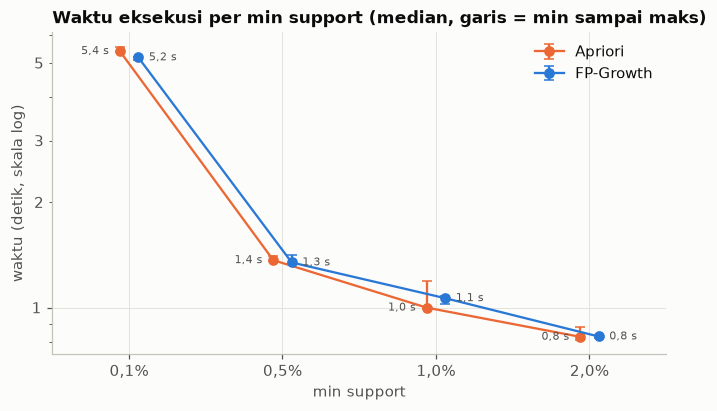

In [12]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
x = np.arange(len(CFG.MIN_SUPPORTS))
for name, color, offset, side in (("Apriori", CFG.ORANGE, -0.06, -1), ("FP-Growth", CFG.BLUE, 0.06, 1)):
    s = summary[summary["algorithm"] == name].set_index("min_support").loc[CFG.MIN_SUPPORTS]
    err = np.vstack([s["median_s"] - s["min_s"], s["max_s"] - s["median_s"]])
    ax.errorbar(x + offset, s["median_s"], yerr=err, marker="o", color=color, capsize=3, label=name)
    for xi, v in zip(x + offset, s["median_s"]):
        ax.annotate(f"{fmt_id(v, 1)} s", (xi, v), xytext=(7 * side, 0), textcoords="offset points",
                    ha="left" if side > 0 else "right", va="center", fontsize=7.5, color=CFG.INK_2)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_id(v, 0 if v >= 1 else 1)))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: fmt_id(v, 0 if v >= 1 else 1) if round(v, 1) in (2, 3, 5, 20, 30, 50) else ""))
ax.set_xticks(x, [pct_id(ms * 100) for ms in CFG.MIN_SUPPORTS])
ax.set_xlim(-0.5, len(x) - 0.5)
ax.set_xlabel("min support")
ax.set_ylabel("waktu (detik, skala log)")
title = "Waktu eksekusi per min support (median, garis = min sampai maks)"
if APRIORI_STANDIN:
    title += "\nApriori: PENGGANTI SEMENTARA, bukan hasil Apriori"
ax.set_title(title)
ax.legend()
save_fig(fig, "t6_waktu_per_min_support.png")

---

# Analisis Hasil Perbandingan <a name="8"></a>

---

Bagian ini merangkum temuan dari bagian 5 sampai 7 dalam empat subbagian. Waktu yang dipakai adalah median tiga pengulangan pada satu mesin lokal, dilengkapi rincian per level Apriori dari `03_apriori`.

## 8.1 Pengaruh Min Support terhadap Performa

Menaikkan min support mempercepat kedua algoritma, tetapi jauh lebih lambat daripada turunnya jumlah pola. Penyebabnya ada pada biaya tetap yang dibayar kedua algoritma.

#### Insights

> 1. Dari 0,1% ke 2%, waktu Apriori turun dari 5,41 menjadi 0,83 detik dan waktu FP-Growth dari 5,19 menjadi 0,83 detik, atau sekitar 6,3 sampai 6,5 kali. Jumlah frequent itemsets pada rentang yang sama turun 252 kali (1.514 menjadi 6).
> 2. Waktu turun jauh lebih sedikit karena kedua algoritma selalu membayar satu pemindaian 1.821.757 transaksi untuk menghitung support 1-itemset, lalu pemangkasan dan penggabungan transaksi.
> 3. Pada 2%, biaya tetap ini praktis seluruh waktunya. Penambangan FP-Growth hanya 0,00006 detik dari 0,83 detik, dan Apriori berhenti di level 2 setelah 15 kandidat tidak ada yang frequent.
> 4. Pada 0,1%, Apriori membayar di level 2. Terdapat 574 item frequent, sehingga semua 164.451 pasangan menjadi kandidat dan hanya 393 (0,24%) yang frequent. Level 2 memakan sekitar separuh total waktu, dan mulai level 3 prune membuat kandidat kecil (1.228, 337, 54, dan 5).
> 5. Pada 0,1%, FP-Growth membayar saat membangun FP-tree. Pembentukan pohon dari transaksi yang sudah digabung memakan 3,33 detik, sedangkan penambangannya 1,75 detik. Pada 0,5% ke atas, pembentukan pohon mencakup 82% sampai 100% waktunya.

## 8.2 Kesamaan Hasil Kedua Algoritma

Frequent itemsets dan rules dari kedua algoritma dibandingkan pada bagian 5 dan 6.

#### Insights

> 1. Pada keempat min support, kedua algoritma menghasilkan himpunan frequent itemsets yang sama persis (1.514, 88, 30, dan 6), tanpa itemset yang hanya ditemukan salah satunya dan tanpa perbedaan count.
> 2. Association rules dengan min confidence 50% juga identik, yaitu 1.387, 7, 1, dan 0 rules dengan support, confidence, dan lift yang sama.
> 3. Kesamaan ini diharapkan karena keduanya algoritma eksak dengan definisi support dan ambang yang sama (`min_count_for`), sehingga perbedaannya hanya pada cara menghitung.
> 4. `03_apriori` dan `04_fpgrowth` juga memvalidasi masing-masing algoritma terhadap `mlxtend` dengan hasil identik.

## 8.3 Perbandingan Waktu Kedua Algoritma

Waktu kedua algoritma dibandingkan pada keempat min support, lalu dikaitkan dengan sifat data DBLP.

#### Insights

> 1. Kedua algoritma praktis setara. Rasio median Apriori terhadap FP-Growth adalah 1,04, 1,02, 0,94, dan 1,00.
> 2. FP-Growth konsisten sedikit lebih cepat hanya pada 0,1% (sekitar 4%, rentang min-maks tidak tumpang tindih). Pada 0,5% dan 2% rentangnya tumpang tindih, dan pada 1% Apriori sedikit lebih cepat. Selisih sekecil ini lebih kecil daripada pengaruh detail implementasi, sehingga data ini tidak mendukung klaim bahwa salah satu algoritma jelas lebih unggul.
> 3. Transaksi pendek dan ekor panjang membuat database kecil. Sebanyak 58,4% author hanya publish di satu venue (`02_transactions`), hanya 536.543 transaksi yang berisi minimal dua item frequent pada 0,1%, dan setelah digabung tersisa 315.694 transaksi unik.
> 4. Pola sedikit dan dangkal. Itemset terpanjang hanya berisi enam item, sehingga Apriori hanya perlu enam pemindaian, dan prune pada level 3 ke atas membuang hampir semua kombinasi.
> 5. Kedua implementasi memakai pra-pemrosesan yang sama, dan Apriori memilih cara penghitungan kandidat yang lebih murah per transaksi. Tanpa pilihan itu, transaksi terpanjang (187 item frequent) membuat enumerasi subset meledak.

## 8.4 Algoritma yang Lebih Sesuai untuk DBLP

Meskipun waktunya setara, FP-Growth lebih sesuai sebagai pilihan utama untuk DBLP, dengan alasan dan batasan berikut.

#### Insights

> 1. Bagian penambangan FP-Growth (1,75 detik pada 0,1%) lebih cepat daripada level 2 ke atas Apriori (sekitar 4,4 detik pada `03_apriori`). Selisih total kecil karena FP-Growth menghabiskan lebih banyak waktu membangun pohon.
> 2. Biaya Apriori tumbuh kuadratik terhadap jumlah item frequent. Dari 2% ke 0,1%, item frequent naik 96 kali tetapi kandidat level 2 naik sekitar 11.000 kali.
> 3. Menurunkan min support di bawah 0,1% (untuk menangkap pola bidang yang lebih kecil) akan menambah item frequent, dan biaya kandidat Apriori diperkirakan tumbuh lebih cepat daripada biaya FP-tree. Ini perkiraan dari pola pertumbuhan kandidat, bukan hasil pengukuran di notebook ini.
> 4. Kedua algoritma ditulis dalam Python murni satu thread, sehingga waktu absolutnya mencerminkan overhead interpreter dan dapat berbeda dari implementasi C atau Java.
> 5. Pengukuran dilakukan tiga kali pada satu mesin, dan variasi antarpengulangan mencapai 19% (Apriori pada 1%: 0,99 sampai 1,19 detik), sehingga selisih median beberapa persen sebaiknya dianggap setara.